Dataset loaded successfully!
Dataset shape: (60, 23)

Column names:
['month', 'year', 'mineral', 'material_scope', 'reporter_country', 'price_month_count', 'mean_tin_price_usd_per_kg', 'realized_monthly_return_volatility_pct', 'refined_imports_tonnes', 'refined_exports_tonnes', 'apparent_refined_consumption_tonnes', 'refined_net_imports_tonnes', 'net_imports_to_consumption_proxy_pct', 'official_net_import_reliance_pct', 'official_reliance_status', 'supply_source', 'supply_data_status', 'price_source', 'tin_price_usd_per_kg', 'monthly_price_change_pct', 'next_3_month_volatility_pct', 'forward_window_end', 'annual_fields_usage']

Annual data used in regression:
 year  realized_monthly_return_volatility_pct  net_imports_to_consumption_proxy_pct
 2021                                6.128356                             76.687500
 2022                               10.830203                             77.402913
 2023                                7.672380                             77.948

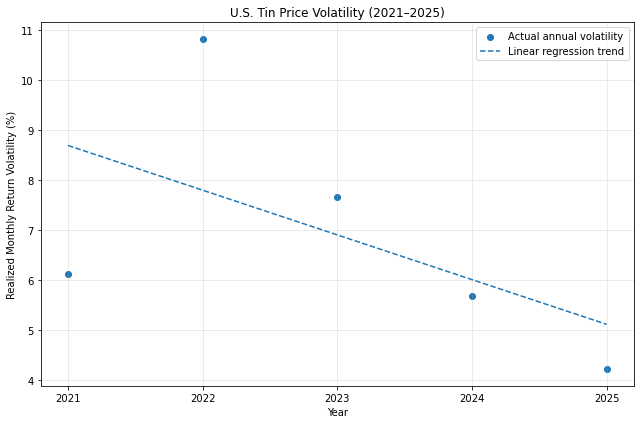

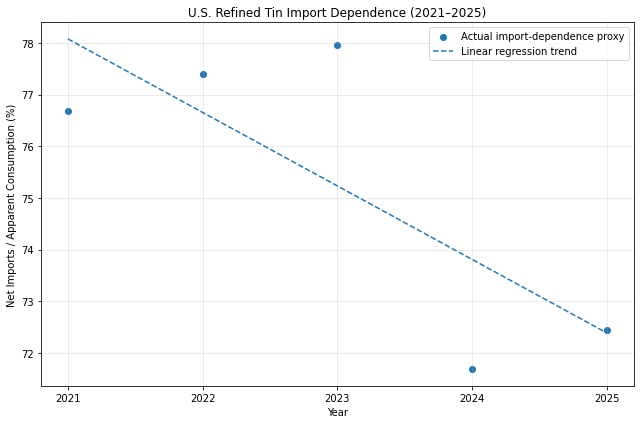


FINAL REGRESSION RESULTS
                       Model   Slope  R-squared  P-value
        Tin Price Volatility -0.8948     0.3169   0.3231
U.S. Import Dependence Proxy -1.4206     0.5840   0.1325

Results saved successfully to:
/home/rameshp/vscode/Semiconductors-DSS/Project_Directory/Final_data/final dataset/Regression_Results

Files created:
- tin_annual_regression_results.csv
- tin_regression_summary.csv


In [5]:

# ============================================================
# TIN PRICE VOLATILITY AND U.S. IMPORT DEPENDENCE REGRESSION
# Period: 2021–2025
# Environment: Local Python / VS Code
# ============================================================


# 1. IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from pathlib import Path


# ============================================================
# 2. LOAD DATASET
# ============================================================

file_path = Path(
    "/home/rameshp/vscode/Semiconductors-DSS/Project_Directory/"
    "Final_data/final dataset/tin_monthly_combined_2021_2025.csv"
)

if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


# ============================================================
# 3. CLEAN COLUMN NAMES
# ============================================================

df.columns = (
    df.columns
    .str.replace("**", "", regex=False)
    .str.strip()
)

print("\nColumn names:")
print(df.columns.tolist())


# ============================================================
# 4. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "year",
    "realized_monthly_return_volatility_pct",
    "net_imports_to_consumption_proxy_pct"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. PREPARE ANNUAL DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df[df["year"].between(2021, 2025)].copy()

# Check that annual values are consistent across monthly rows.
annual_columns = [
    "realized_monthly_return_volatility_pct",
    "net_imports_to_consumption_proxy_pct"
]

for col in annual_columns:
    yearly_counts = df.groupby("year")[col].nunique(dropna=True)

    inconsistent_years = yearly_counts[yearly_counts > 1]

    if not inconsistent_years.empty:
        raise ValueError(
            f"Inconsistent annual values found in {col} "
            f"for years: {inconsistent_years.index.tolist()}"
        )

# Annual values are repeated across monthly records.
# Keep one observation per year to avoid duplication.

annual_data = (
    df.groupby("year", as_index=False)
    .agg({
        "realized_monthly_return_volatility_pct": "first",
        "net_imports_to_consumption_proxy_pct": "first"
    })
)

annual_data = (
    annual_data
    .dropna(subset=annual_columns)
    .sort_values("year")
    .reset_index(drop=True)
)

print("\nAnnual data used in regression:")
print(annual_data.to_string(index=False))

print("\nIndependent annual observations:", len(annual_data))

if len(annual_data) != 5:
    raise ValueError(
        "Expected five complete annual observations from 2021 to 2025."
    )


# ============================================================
# 6. INDEPENDENT VARIABLE
# ============================================================

# X = 0 represents 2021
# X = 1 represents 2022
# ...
# X = 4 represents 2025

X = annual_data["year"].to_numpy() - 2021


# ============================================================
# 7. MODEL A: PRICE VOLATILITY
# ============================================================

y_volatility = annual_data[
    "realized_monthly_return_volatility_pct"
].to_numpy()

model_volatility = linregress(X, y_volatility)

annual_data["predicted_volatility"] = (
    model_volatility.intercept
    + model_volatility.slope * X
)

print("\n======================================")
print("MODEL A: TIN PRICE VOLATILITY")
print("======================================")

print(
    f"Regression equation: "
    f"Y = {model_volatility.intercept:.3f} "
    f"{model_volatility.slope:+.3f}X"
)

print(f"Slope: {model_volatility.slope:.4f}")
print(f"R-squared: {model_volatility.rvalue**2:.4f}")
print(f"P-value: {model_volatility.pvalue:.4f}")

print(
    f"Annual change: {model_volatility.slope:.3f} "
    "percentage points per year"
)


# ============================================================
# 8. MODEL B: IMPORT DEPENDENCE
# ============================================================

y_imports = annual_data[
    "net_imports_to_consumption_proxy_pct"
].to_numpy()

model_imports = linregress(X, y_imports)

annual_data["predicted_import_dependence"] = (
    model_imports.intercept
    + model_imports.slope * X
)

print("\n======================================")
print("MODEL B: U.S. IMPORT DEPENDENCE")
print("======================================")

print(
    f"Regression equation: "
    f"Y = {model_imports.intercept:.3f} "
    f"{model_imports.slope:+.3f}X"
)

print(f"Slope: {model_imports.slope:.4f}")
print(f"R-squared: {model_imports.rvalue**2:.4f}")
print(f"P-value: {model_imports.pvalue:.4f}")

print(
    f"Annual change: {model_imports.slope:.3f} "
    "percentage points per year"
)


# ============================================================
# 9. GRAPH A: PRICE VOLATILITY
# ============================================================

years = annual_data["year"].to_numpy()

plt.figure(figsize=(9, 6))

plt.scatter(
    years,
    y_volatility,
    label="Actual annual volatility"
)

plt.plot(
    years,
    annual_data["predicted_volatility"].to_numpy(),
    linestyle="--",
    label="Linear regression trend"
)

plt.title("U.S. Tin Price Volatility (2021–2025)")
plt.xlabel("Year")
plt.ylabel("Realized Monthly Return Volatility (%)")
plt.xticks(years)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 10. GRAPH B: IMPORT DEPENDENCE
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    years,
    y_imports,
    label="Actual import-dependence proxy"
)

plt.plot(
    years,
    annual_data["predicted_import_dependence"].to_numpy(),
    linestyle="--",
    label="Linear regression trend"
)

plt.title("U.S. Refined Tin Import Dependence (2021–2025)")
plt.xlabel("Year")
plt.ylabel("Net Imports / Apparent Consumption (%)")
plt.xticks(years)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 11. REGRESSION SUMMARY
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Tin Price Volatility",
        "U.S. Import Dependence Proxy"
    ],
    "Slope": [
        model_volatility.slope,
        model_imports.slope
    ],
    "R-squared": [
        model_volatility.rvalue**2,
        model_imports.rvalue**2
    ],
    "P-value": [
        model_volatility.pvalue,
        model_imports.pvalue
    ]
})

print("\n======================================")
print("FINAL REGRESSION RESULTS")
print("======================================")

print(results.round(4).to_string(index=False))


# ============================================================
# 12. EXPORT RESULTS
# ============================================================

output_folder = file_path.parent / "Regression_Results"
output_folder.mkdir(parents=True, exist_ok=True)

annual_data.to_csv(
    output_folder / "tin_annual_regression_results.csv",
    index=False
)

results.to_csv(
    output_folder / "tin_regression_summary.csv",
    index=False
)

print("\nResults saved successfully to:")
print(output_folder.resolve())

print("\nFiles created:")
print("- tin_annual_regression_results.csv")
print("- tin_regression_summary.csv")
